In [2]:
import pandas as pd 

data = pd.read_csv('../bdd100k_quantitativo.csv')
data


,Image_Name,Number of people,Number of cars,Number of buses or trucks,Is there any red traffic light,Is there any green traffic light,Is there any traffic signs,Number of rider in motorcyles or bikes,What is the weather (clear/overcast/rainy/snowy/foggy/partly cloud/undefined),Time of the day (daytime/night/dawn)
0,0004a4c0-d4dff0ad.jpg,0,3,0,No,No,No,0,Partly cloudy,Daytime
1,00054602-3bf57337.jpg,0,1,0,No,No,No,0,Partly cloudy,Daytime
2,00067cfb-e535423e.jpg,2,0,0,No,No,No,0,Partly cloudy,Daytime
3,00091078-59817bb0.jpg,0,2,1,No,No,No,0,Partly cloudy,Night
4,0010bf16-a457685b.jpg,0,1,1,No,No,No,0,Partly cloudy,Daytime
...,...,...,...,...,...,...,...,...,...,...
6995,fdb7ff6e-bcaa5d96.jpg,0,1,0,No,No,No,0,Partly cloudy,Daytime
6996,fdbffb41-a07c5660.jpg,0,0,0,No,No,Yes,0,Foggy,Daytime
6997,fdd1152e-39c77902.jpg,0,0,0,No,No,No,1,Partly cloudy,Daytime
6998,fdf00ecc-30d49dac.jpg,0,10,0,No,No,No,0,Snowy,Daytime


In [3]:
data_np = data.to_numpy()
data_np

array([['0004a4c0-d4dff0ad.jpg', 0, 3, ..., 0, 'Partly cloudy',
        'Daytime'],
       ['00054602-3bf57337.jpg', 0, 1, ..., 0, 'Partly cloudy',
        'Daytime'],
       ['00067cfb-e535423e.jpg', 2, 0, ..., 0, 'Partly cloudy',
        'Daytime'],
       ...,
       ['fdd1152e-39c77902.jpg', 0, 0, ..., 1, 'Partly cloudy',
        'Daytime'],
       ['fdf00ecc-30d49dac.jpg', 0, 10, ..., 0, 'Snowy', 'Daytime'],
       ['fe1f2409-5b415eb7.jpg', 0, 0, ..., 0, 'Partly cloudy',
        'Daytime']], shape=(7000, 10), dtype=object)

In [4]:
import json 


IMGS_DIR = "../bdd100k-dataset/bdd100k/bdd100k/images/100k/train/trainA/"


with open("../bdd100k-dataset/bdd100k_labels_release/bdd100k/labels/bdd100k_labels_images_train.json", "r") as f:
    data = json.load(f)

data_gt = {item['name']: item for item in data}

In [5]:
import numpy as np

d = {"Number of people": "person"}

count_img_not_found = 0
gt_counts = []
prd_counts = []

for row in data_np[1:]:
    img = row[0]
    if img in data_gt:
        img_gt = data_gt[img]
        
        n_people = len([obj for obj in img_gt['labels'] if 'category' in obj and obj['category'] == 'person' ])
        gt_counts.append(n_people)
        prd_counts.append(row[1])
    else:
        count_img_not_found += 1
    
print(count_img_not_found)

gt_counts = np.array(gt_counts)
prd_counts = np.array(prd_counts)

np.mean(np.abs(gt_counts - prd_counts))


4027


np.float64(1.6164199192462987)

{'name': '192792cc-6d0a0709.jpg', 'attributes': {'weather': 'clear', 'scene': 'city street', 'timeofday': 'night'}, 'timestamp': 10000, 'labels': [{'category': 'traffic light', 'attributes': {'occluded': False, 'truncated': False, 'trafficLightColor': 'red'}, 'manualShape': True, 'manualAttributes': True, 'box2d': {'x1': 290.481826, 'y1': 329.399768, 'x2': 305.669315, 'y2': 356.39975}, 'id': 272727}, {'category': 'traffic light', 'attributes': {'occluded': False, 'truncated': False, 'trafficLightColor': 'red'}, 'manualShape': True, 'manualAttributes': True, 'box2d': {'x1': 700.544045, 'y1': 265.274813, 'x2': 712.356535, 'y2': 302.399786}, 'id': 272728}, {'category': 'traffic light', 'attributes': {'occluded': False, 'truncated': False, 'trafficLightColor': 'red'}, 'manualShape': True, 'manualAttributes': True, 'box2d': {'x1': 130.169438, 'y1': 361.462246, 'x2': 152.106923, 'y2': 385.087231}, 'id': 272729}, {'category': 'traffic sign', 'attributes': {'occluded': False, 'truncated': Fals

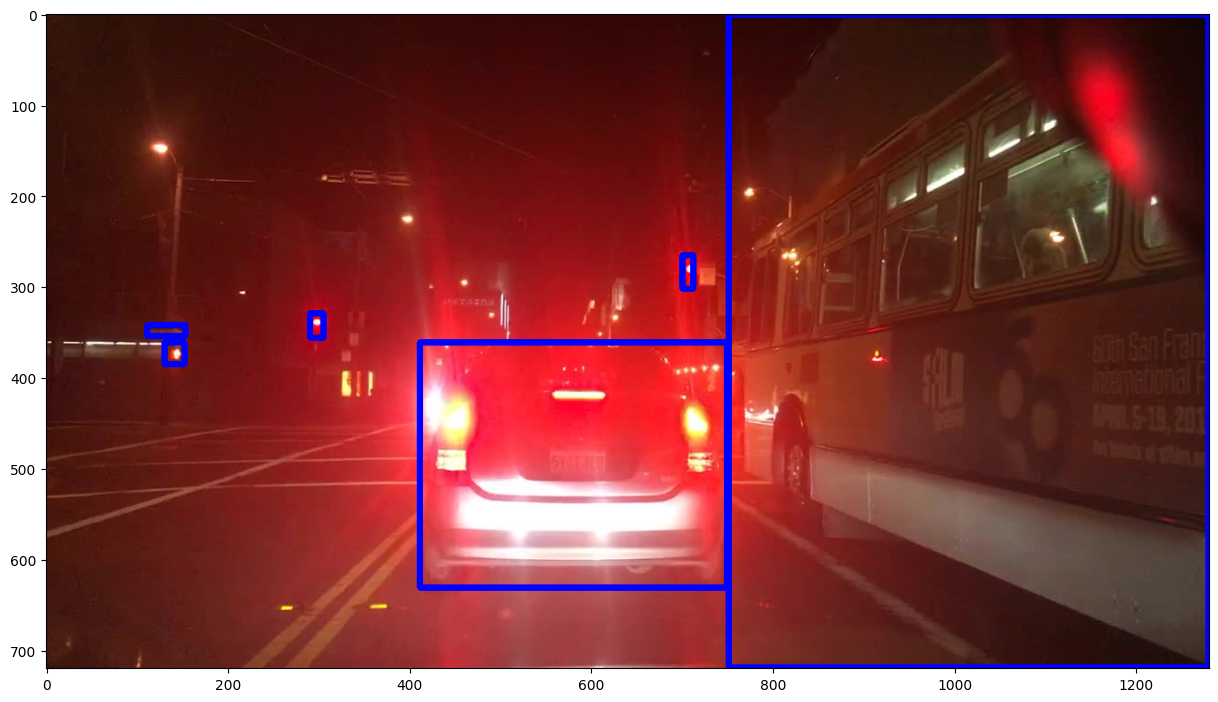

In [ ]:
import cv2 
import json 
import numpy as np 
from PIL import Image 
import matplotlib.pyplot as plt 


IMGS_DIR = "../bdd100k-dataset/bdd100k/bdd100k/images/100k/train/trainA/"

with open("../bdd100k-dataset/bdd100k_labels_release/bdd100k/labels/bdd100k_labels_images_train.json", "r") as f:
    data = json.load(f)

data_rapida = {item['name']: item for item in data}


def load_img_with_bbs(path):
    img = np.array(Image.open(f"{IMGS_DIR}{path}"))

    objects = data_rapida[path]['labels']

    view = img.copy()

    for obj in objects:
        if 'box2d' in obj:
            bbox = obj['box2d']
            cv2.rectangle(view, (int(bbox['x1']), int(bbox['y1'])), (int (bbox['x2']), int(bbox['y2'])), (0, 0, 255), 5)

    return view, data_rapida[path]



    

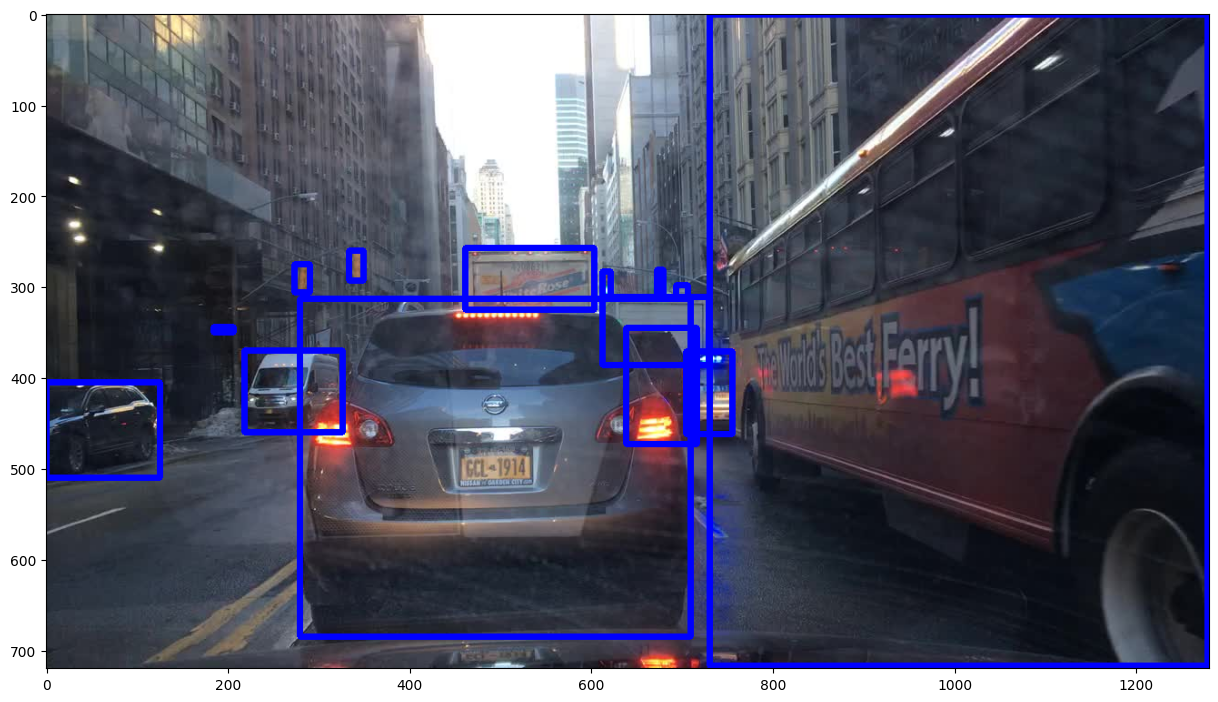

In [26]:
from pprint import pprint 
view, gt = load_img_with_bbs("00091078-59817bb0.jpg")

plt.figure(figsize=(15, 10))
plt.imshow(view)

#pprint (gt)
